# Blast Radius: do ontologies help LLMs reason about system topology?

**A small, pre-registered benchmark in two experiments.**

> *Thesis:* "LLMs grounded in an ontology are better at reasoning about system topology than LLMs alone."

| | Experiment 1 | Experiment 2 |
|---|---|---|
| Question | Does an ontology (RDF + RDFS/OWL schema, queried with SPARQL) beat an LLM alone, and beat code with the same schema documentation? | Do **executable** definitions encoded in the ontology beat the same definitions written as **prose**? |
| Status | Complete: pre-registered TEST run and analysis | Definitions verified, DEV run done, pre-registered; **TEST not yet run** |
| Headline | **Not supported.** Ontology (C) and schema-documented code (B+) tie: ΔF1 = −0.005 [−0.055, +0.055] | DEV only (18 questions): ontology with rules (C2) and Python helpers (B++) both perfect; prose (B+) 0.89 |

Every number and figure below is computed live from the committed results and data. Nothing is pasted in.

In [1]:
import json, re, sys, collections
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
EXP1, EXP2 = ROOT / "exp1", ROOT / "exp2"
sys.path[:0] = [str(EXP1), str(EXP2)]   # exp1 modules are also importable after `pip install -e .`
import truth                                  # NetworkX ground truth (exp1 code, used for both experiments)
from score import paired_bootstrap            # exp1 per-question bootstrap
from score2 import cluster_bootstrap          # exp2 cluster bootstrap over question texts

def truth_for(exp, n):
    truth.DATA = EXP1 / "data" if exp == 1 else EXP2 / "data"
    return truth.Truth(n)

# ---- figure style: validated categorical palette; colour follows the condition in every figure
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#a19f97", "#e4e3df"
COLOR = {"A": "#2a78d6", "B": "#eb6834", "Bplus": "#1baf7a", "C": "#eda100",   # exp1 (slots 1-4)
         "Bplusplus": "#4a3aa7", "C2": "#008300"}                                 # exp2 additions
MARKER = {"A": "o", "B": "s", "Bplus": "^", "C": "D", "Bplusplus": "v", "C2": "P"}
NAME = {"A": "A  LLM only", "B": "B  Python", "Bplus": "B+ Python + schema doc", "C": "C  SPARQL + ontology",
        "Bplusplus": "B++ Python + helpers", "C2": "C2 SPARQL + rule ontology"}
SHORT = {"A": "A", "B": "B", "Bplus": "B+", "C": "C", "Bplusplus": "B++", "C2": "C2"}
NODES = {20: 24, 100: 117, 500: 553}          # exp1 node counts (replicas included)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110,
})
pd.set_option("display.precision", 3)

s1 = pd.read_csv(EXP1 / "results" / "scores_test.csv")       # exp1 TEST scores
s2 = pd.read_csv(EXP2 / "results" / "scores_dev.csv")        # exp2 DEV scores (TEST not run yet)
print(f"exp1 TEST rows: {len(s1)} ({s1.qid.nunique()} questions x {s1.condition.nunique()} conditions)")
print(f"exp2 DEV rows:  {len(s2)} ({s2.qid.nunique()} questions x {s2.condition.nunique()} conditions)")

exp1 TEST rows: 364 (91 questions x 4 conditions)
exp2 DEV rows:  63 (21 questions x 3 conditions)


## 1. The domain: a synthetic infrastructure graph

Each graph is a company's infrastructure: **services** (some **customer-facing**, each with a **tier** 1-3),
**databases**, **queues**, **teams**, **regions** and **SLAs**, linked by `dependsOn` (transitive), `ownedBy`,
`deployedIn`, `hasSLA` and `replicaOf`. The generator (`gen.py`) builds a layered DAG with skewed fan-out
(a few hub nodes with many dependents), region locality, cross- and same-region replicas, and **planted** cases:
tier-1 → tier-3 rule violations, a database lost deep in a dependency chain, and a service that survives a region
failure only through its replica. Three sizes, each from a fixed seed. Ground truth is computed independently
with NetworkX (`truth.py`).

In [2]:
rows = []
for n in (20, 100, 500):
    t = truth_for(1, n)
    types = collections.Counter(v["type"] for v in t.nodes.values())
    rels = collections.Counter(r for _, r, _ in t.edges)
    cross = sum(t.region[a] != t.region[b] for a, b in t.rep.edges)
    rows.append({"graph (nodes)": len(t.nodes), "services": types["Service"] + types["CustomerFacingService"],
                 "customer-facing": types["CustomerFacingService"], "databases": types["Database"],
                 "queues": types["Queue"], "regions": types["Region"], "SLAs": types["SLA"],
                 "dependsOn edges": rels["dependsOn"], "replicas (cross/same region)": f"{cross}/{rels['replicaOf'] - cross}",
                 "max in-degree": max(d for _, d in t.dep.in_degree()),
                 "longest chain": max(t.longest_chain(x) for x in t.dep),
                 "planted violations": len(t.tier_violations())})
display(pd.DataFrame(rows, index=["small", "medium", "large"]).T)

,small,medium,large
graph (nodes),24,117,553
services,12,63,329
customer-facing,5,15,67
databases,4,27,124
queues,1,5,25
regions,2,3,5
SLAs,3,14,55
dependsOn edges,14,121,592
replicas (cross/same region),3/3,25/5,123/30
max in-degree,4,17,32


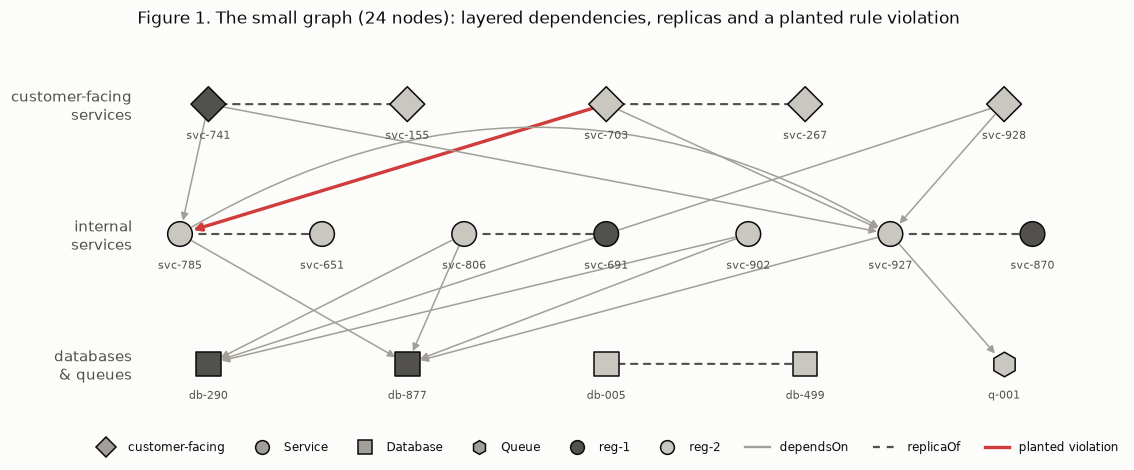

In [3]:
# Figure 1 - the 24-node graph. Shape = class, fill = region, dashed = replicaOf, red = planted tier-rule violation.
t = truth_for(1, 20)
layer = {"CustomerFacingService": 3, "Service": 2, "Database": 1, "Queue": 1}
comps = [x for x in t.nodes if t.nodes[x]["type"] in layer]
replica_of = {s: o for s, r, o in t.edges if r == "replicaOf"}
pos = {}
for lvl in (3, 2, 1):                       # each replica is placed right after its primary
    row = [x for x in comps if layer[t.nodes[x]["type"]] == lvl]
    xs = []
    for p in sorted((x for x in row if x not in replica_of), key=lambda x: (t.region[x], x)):
        xs += [p] + sorted(r for r in row if replica_of.get(r) == p)
    for i, x in enumerate(xs):
        pos[x] = ((i + 0.5) / len(xs), lvl)
shape = {"CustomerFacingService": "D", "Service": "o", "Database": "s", "Queue": "h"}
region_fill = {"reg-1": INK2, "reg-2": "#c9c7bf"}
viol = set(t.tier_violations())

fig, ax = plt.subplots(figsize=(11, 4.6))
for a, b in t.dep.edges:
    c, w = ("#d03b3b", 2.2) if (a, b) in viol else (MUTED, 1.0)
    same_row = pos[a][1] == pos[b][1]        # curve arrows within a row so they do not cross other nodes
    ax.annotate("", xy=pos[b], xytext=pos[a], arrowprops=dict(arrowstyle="-|>", color=c, lw=w,
                shrinkA=9, shrinkB=9, mutation_scale=10,
                connectionstyle=f"arc3,rad={-0.3 if same_row else 0}"), zorder=1)
for a, b in t.rep.edges:
    ax.annotate("", xy=pos[b], xytext=pos[a], zorder=1, arrowprops=dict(arrowstyle="-", ls=(0, (3, 3)), color=INK2,
                lw=1.4, shrinkA=9, shrinkB=9))
for typ, m in shape.items():
    xs = [x for x in comps if t.nodes[x]["type"] == typ]
    ax.scatter([pos[x][0] for x in xs], [pos[x][1] for x in xs], marker=m, s=260,
               c=[region_fill[t.region[x]] for x in xs], edgecolors=INK, linewidths=1, zorder=3)
for x in comps:
    ax.text(pos[x][0], pos[x][1] - 0.2, x, ha="center", va="top", fontsize=7.5, color=INK2)
ax.set_yticks([3, 2, 1], ["customer-facing\nservices", "internal\nservices", "databases\n& queues"])
ax.set_xticks([]); ax.set_ylim(0.55, 3.55); ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
handles = [plt.Line2D([], [], marker=m, ls="", color=MUTED, mec=INK, ms=9, label=k.replace("CustomerFacingService", "customer-facing"))
           for k, m in shape.items()] + \
          [plt.Line2D([], [], marker="o", ls="", color=c, mec=INK, ms=9, label=r) for r, c in region_fill.items()] + \
          [plt.Line2D([], [], color=MUTED, label="dependsOn"), plt.Line2D([], [], color=INK2, ls=(0, (3, 3)), label="replicaOf"),
           plt.Line2D([], [], color="#d03b3b", lw=2.2, label="planted violation")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=9, frameon=False, fontsize=8)
ax.set_title("Figure 1. The small graph (24 nodes): layered dependencies, replicas and a planted rule violation",
             loc="left", fontsize=11)
plt.show()

## 2. Experiment 1 design

Four conditions answer the **same questions** about the **same graphs** with the **same model** (Haiku 4.5,
temperature 0, 8192 output tokens). Each returns a machine-parseable answer (a set of IDs, a boolean or a number),
scored automatically against the NetworkX ground truth.

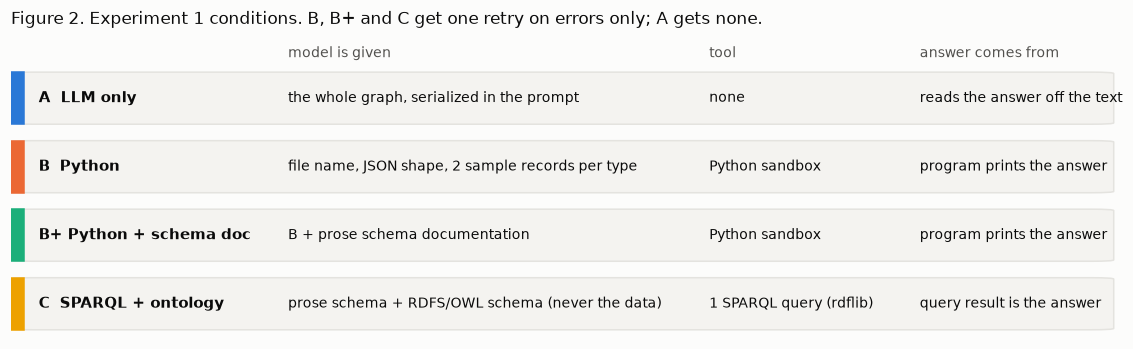

In [4]:
# Figure 2 - what each condition sees and does.
spec = [("A", "the whole graph, serialized in the prompt", "none", "reads the answer off the text"),
        ("B", "file name, JSON shape, 2 sample records per type", "Python sandbox", "program prints the answer"),
        ("Bplus", "B + prose schema documentation", "Python sandbox", "program prints the answer"),
        ("C", "prose schema + RDFS/OWL schema (never the data)", "1 SPARQL query (rdflib)", "query result is the answer")]
COLS = (0.25, 0.63, 0.82)
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, len(spec) + 0.45)
for col, head in zip(COLS, ("model is given", "tool", "answer comes from")):
    ax.text(col, len(spec) + 0.05, head, fontsize=9, color=INK2, va="bottom")
for i, (c, given, tool, ans) in enumerate(spec):
    y = len(spec) - 1 - i
    ax.add_patch(FancyBboxPatch((0.0, y + 0.12), 0.995, 0.76, boxstyle="round,pad=0,rounding_size=0.02",
                                fc="#f4f3f0", ec=GRID, lw=1))
    ax.add_patch(plt.Rectangle((0.0, y + 0.12), 0.012, 0.76, color=COLOR[c]))
    ax.text(0.025, y + 0.5, NAME[c], va="center", fontsize=10, weight="bold")
    for col, txt in zip(COLS, (given, tool, ans)):
        ax.text(col, y + 0.5, txt, va="center", fontsize=9)
ax.set_title("Figure 2. Experiment 1 conditions. B, B+ and C get one retry on errors only; A gets none.",
             loc="left", fontsize=11)
plt.show()

In [5]:
qs1 = pd.DataFrame(json.loads((EXP1 / "data" / "questions.json").read_text()))
example = qs1[qs1["size"] == 100].groupby("level").first()["text"].str.slice(0, 95) + "..."
levels = pd.DataFrame({
    "what it tests": {"L1": "lookup", "L2": "multi-hop (transitive)", "L3": "aggregation / negation",
                      "L4": "failure / constraint", "L5": "out-of-schema (path arithmetic)"},
    "TEST questions": qs1[qs1.split == "test"].groupby("level").size(),
    "in thesis test": {"L1": "no", "L2": "yes", "L3": "yes", "L4": "yes", "L5": "no"},
    "example (100-node graph)": example})
display(levels)

,what it tests,TEST questions,in thesis test,example (100-node graph)
L1,lookup,21,no,Which team owns svc-236?...
L2,multi-hop (transitive),21,yes,"What are all upstream dependencies of svc-520,..."
L3,aggregation / negation,20,yes,How many services of any kind (including repli...
L4,failure / constraint,20,yes,"If region reg-2 fails, which SLAs are breached..."
L5,out-of-schema (path arithmetic),9,no,What is the minimum number of dependsOn edges ...


**Pre-registered test** (written to `PREREG.md` and committed before any TEST question was sent):
mean paired F1 difference **C − B+** on TEST levels L2-L4 (n = 61), 95% bootstrap CI (10,000 resamples).
*Supported* only if the lower bound is above 0. The B+ control isolates "knowing the schema" from "having a formal
ontology". All prompts were frozen after DEV; one tuning round was applied to every condition equally.

## 3. Experiment 1 results

In [6]:
core1 = s1[s1.level.isin(["L2", "L3", "L4"])]
rows = []
for other in ("Bplus", "A", "B"):
    r = paired_bootstrap(core1, "C", other)
    verdict = ("supported" if r["lo"] > 0 else "contradicted" if r["hi"] < 0 else "not supported (CI includes 0)")
    rows.append({"comparison": f"C - {SHORT[other]}", "mean ΔF1": r["diff"], "95% CI low": r["lo"],
                 "95% CI high": r["hi"], "n": r["n"],
                 "role": "PRIMARY (pre-registered)" if other == "Bplus" else "secondary", "reading": verdict})
display(pd.DataFrame(rows).set_index("comparison"))

,mean ΔF1,95% CI low,95% CI high,n,role,reading
comparison,,,,,,
C - B+,-0.005,-0.055,0.055,61,PRIMARY (pre-registered),not supported (CI includes 0)
C - A,0.163,0.083,0.250,61,secondary,supported
C - B,0.057,-0.035,0.158,61,secondary,not supported (CI includes 0)


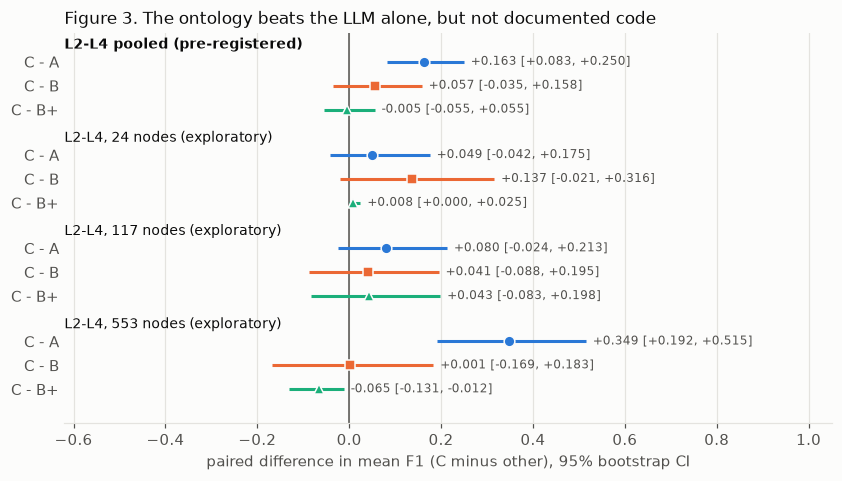

In [7]:
# Figure 3 - paired differences with 95% CIs: pre-registered pooled test first, per-size rows exploratory.
groups = [("L2-L4 pooled (pre-registered)", core1)] + \
         [(f"L2-L4, {NODES[n]} nodes (exploratory)", core1[core1["size"] == n]) for n in (20, 100, 500)]
fig, ax = plt.subplots(figsize=(9, 4.6)); y, ticks = 0, []
for label, sub in groups:
    ax.text(-0.62, y + 0.55, label, fontsize=9, weight="bold" if "pre-reg" in label else "normal")
    for other in ("A", "B", "Bplus"):
        r = paired_bootstrap(sub, "C", other)
        ax.errorbar(r["diff"], y, xerr=[[r["diff"] - r["lo"]], [r["hi"] - r["diff"]]], fmt=MARKER[other],
                    color=COLOR[other], ms=7, mec=SURFACE, lw=2, zorder=3)
        ax.text(r["hi"] + 0.015, y, f"{r['diff']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]", va="center", fontsize=8, color=INK2)
        ticks.append((y, f"C - {SHORT[other]}")); y -= 1
    y -= 0.9
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(*zip(*ticks)); ax.tick_params(axis="y", length=0)
ax.set_xlim(-0.62, 1.05); ax.set_ylim(y + 0.5, 1.2); ax.grid(axis="x", color=GRID); ax.spines["left"].set_visible(False)
ax.set_xlabel("paired difference in mean F1 (C minus other), 95% bootstrap CI")
ax.set_title("Figure 3. The ontology beats the LLM alone, but not documented code", loc="left", fontsize=11)
plt.show()

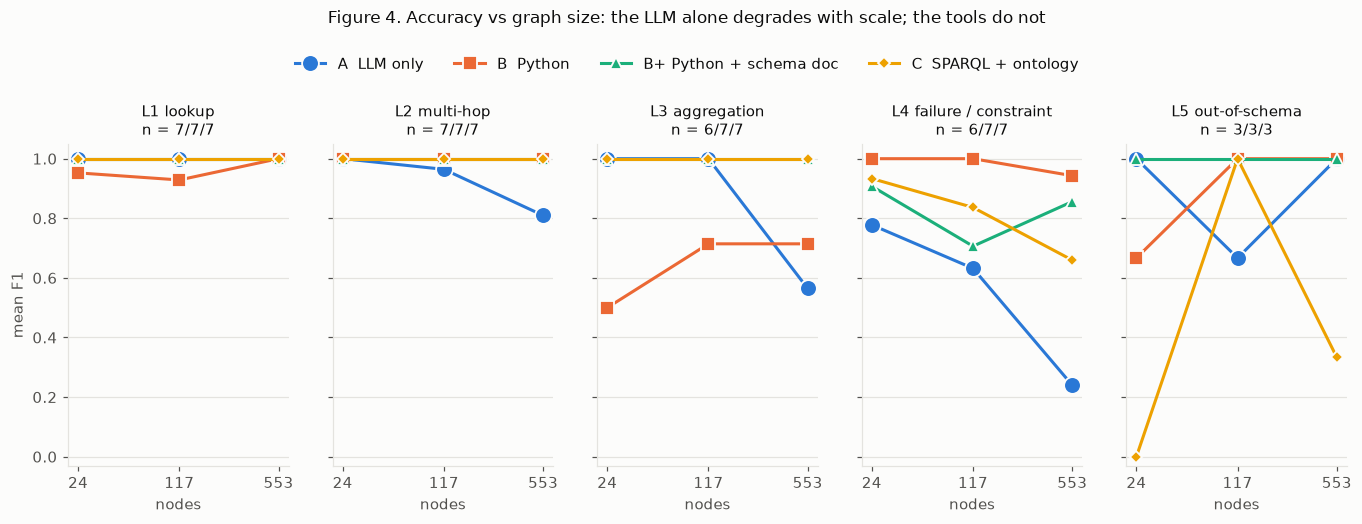

In [8]:
# Figure 4 - F1 vs graph size, one panel per level (markers shrink A -> C so ties stay visible as rings).
sizes, conds = (20, 100, 500), ["A", "B", "Bplus", "C"]
size_ms = {"A": 11, "B": 9, "Bplus": 7.5, "C": 6}
titles = {"L1": "L1 lookup", "L2": "L2 multi-hop", "L3": "L3 aggregation", "L4": "L4 failure / constraint", "L5": "L5 out-of-schema"}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8), sharey=True)
for ax, (lvl, title) in zip(axes, titles.items()):
    m = s1[s1.level == lvl].pivot_table(index="size", columns="condition", values="f1")
    for c in conds:
        ax.plot([NODES[s] for s in sizes], m.loc[list(sizes), c], color=COLOR[c], marker=MARKER[c], lw=2,
                ms=size_ms[c], mec=SURFACE, mew=1.2, label=NAME[c])
    n = s1[(s1.level == lvl) & (s1.condition == "A")].groupby("size").size()
    ax.set_title(f"{title}\nn = {'/'.join(str(n[s]) for s in sizes)}", fontsize=10)
    ax.set_xscale("log"); ax.set_xticks([NODES[s] for s in sizes], [str(NODES[s]) for s in sizes]); ax.minorticks_off()
    ax.set_ylim(-0.03, 1.05); ax.grid(axis="y", color=GRID); ax.set_xlabel("nodes")
axes[0].set_ylabel("mean F1")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.12))
fig.suptitle("Figure 4. Accuracy vs graph size: the LLM alone degrades with scale; the tools do not", y=1.2, fontsize=11)
plt.show()

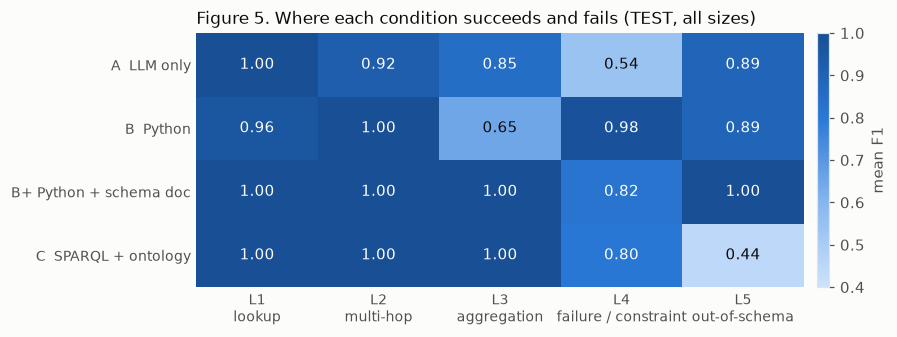

In [9]:
# Figure 5 - mean F1 by condition x level (sequential single-hue ramp, values printed in every cell).
heat = s1.pivot_table(index="condition", columns="level", values="f1").loc[["A", "B", "Bplus", "C"]]
from matplotlib.colors import LinearSegmentedColormap
ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95"])
fig, ax = plt.subplots(figsize=(7.5, 3.0))
im = ax.imshow(heat.values, cmap=ramp, vmin=0.4, vmax=1.0, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10, color="white" if v > 0.8 else INK)
ax.set_xticks(range(5), [titles[l].replace(" ", "\n", 1) for l in heat.columns], fontsize=9, rotation=0)
ax.set_yticks(range(4), [NAME[c] for c in heat.index], fontsize=9)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="mean F1")
ax.set_title("Figure 5. Where each condition succeeds and fails (TEST, all sizes)", loc="left", fontsize=11)
plt.show()

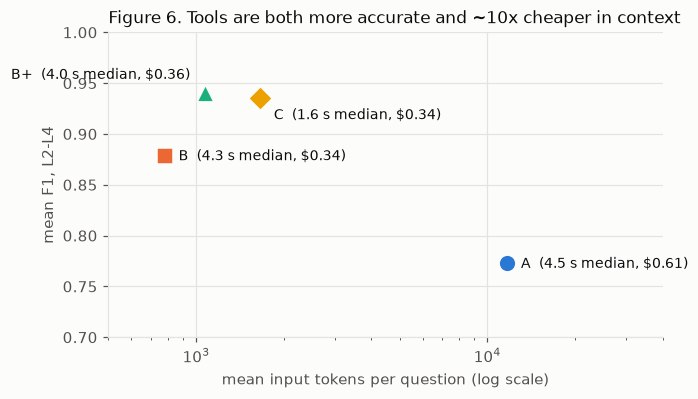

,parsed,retry_rate,hallucinated_ids,timeouts,median_latency_s
condition,,,,,
A,0.978,0.000,0,0,4.511
B,1.000,0.033,0,0,4.284
Bplus,1.000,0.000,0,0,3.972
C,0.989,0.066,0,0,1.567


In [10]:
# Figure 6 - cost of accuracy: mean input tokens per question vs F1 on the thesis levels.
eff = s1.groupby("condition").agg(tokens_in=("tokens_in", "mean"), latency=("latency_s", "median"),
                                  cost=("cost_usd", "sum"))
eff["f1_L2_L4"] = core1.groupby("condition").f1.mean()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for c, r in eff.iterrows():
    ax.scatter(r.tokens_in, r.f1_L2_L4, s=120, color=COLOR[c], marker=MARKER[c], edgecolors=SURFACE, zorder=3)
    dx, dy = {"Bplus": (-10, 9), "C": (9, -14)}.get(c, (9, -3))
    ax.annotate(f"{SHORT[c]}  ({r.latency:.1f} s median, ${r.cost:.2f})", (r.tokens_in, r.f1_L2_L4),
                xytext=(dx, dy), textcoords="offset points", fontsize=9, ha="right" if dx < 0 else "left")
ax.set_xscale("log"); ax.set_xlim(500, 40000); ax.set_ylim(0.7, 1.0); ax.grid(color=GRID)
ax.set_xlabel("mean input tokens per question (log scale)"); ax.set_ylabel("mean F1, L2-L4")
ax.set_title("Figure 6. Tools are both more accurate and ~10x cheaper in context", loc="left", fontsize=11)
plt.show()
display(s1.groupby("condition").agg(parsed=("parsed", "mean"), retry_rate=("retries", lambda x: (x > 0).mean()),
        hallucinated_ids=("n_halluc", "sum"), timeouts=("timeouts", "sum"), median_latency_s=("latency_s", "median")))

## 4. Where the ontology condition failed: region-failure questions

C produced valid SPARQL for 99% of questions, yet it got **9 of its 12 non-survivor region-failure questions wrong**.
Each is a *valid query with the wrong logic*. The hard part is a universally quantified condition over a group
defined by a property path: *a node is lost if **every** member of its replica group is in the failed region*.
In SPARQL that needs a double negation, and the model wrote it three different wrong ways.

,kind,size,precision,recall,f1,pattern
qid,,,,,,
100-L4-03,region_sla,100,0.615,1.000,0.762,"1. footprint tested per member, not per group"
100-L4-07,region_down,100,0.381,1.000,0.552,"1. footprint tested per member, not per group"
500-L4-03,region_down,500,0.597,1.000,0.748,"1. footprint tested per member, not per group"
500-L4-06,region_sla,500,0.537,1.000,0.699,"1. footprint tested per member, not per group"
500-L4-09,region_sla,500,0.472,1.000,0.641,"1. footprint tested per member, not per group"
100-L4-09,region_down,100,0.556,0.526,0.541,2. 'service is lost' filter scoped outside the...
20-L4-06,region_down,20,1.000,0.429,0.600,2. 'service is lost' filter scoped outside the...
500-L4-04,region_down,500,0.615,0.465,0.530,2. 'service is lost' filter scoped outside the...
500-L4-07,region_count_down,500,0.000,0.000,0.000,3. only services counted as lost dependencies


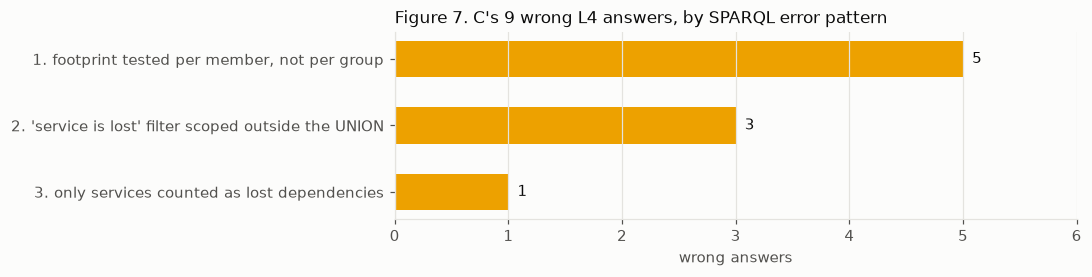

In [11]:
c_l4 = s1[(s1.condition == "C") & (s1.level == "L4")]
wrong = sorted(c_l4[c_l4.f1 < 1].qid)
pattern = {**dict.fromkeys(["100-L4-03", "100-L4-07", "500-L4-03", "500-L4-06", "500-L4-09"], "1. footprint tested per member, not per group"),
           **dict.fromkeys(["20-L4-06", "100-L4-09", "500-L4-04"], "2. 'service is lost' filter scoped outside the UNION"),
           "500-L4-07": "3. only services counted as lost dependencies"}
assert wrong == sorted(pattern), "pattern labels must cover exactly C's wrong L4 answers"
fail = c_l4[c_l4.qid.isin(wrong)].assign(pattern=lambda d: d.qid.map(pattern))
display(fail[["qid", "kind", "size", "precision", "recall", "f1", "pattern"]].sort_values(["pattern", "qid"]).set_index("qid"))

counts = fail.pattern.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 2.2))
ax.barh(counts.index[::-1], counts.values[::-1], color=COLOR["C"], height=0.55)
for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 0.08, i, str(v), va="center", fontsize=10)
ax.set_xlabel("wrong answers"); ax.set_xlim(0, 6); ax.grid(axis="x", color=GRID)
ax.set_title("Figure 7. C's 9 wrong L4 answers, by SPARQL error pattern", loc="left", fontsize=11)
plt.show()

The difference between the most common wrong pattern and a correct query is one level of negation:

```sparql
# Pattern 1 (wrong): binds ONE group member ?m and checks that member is only in reg-2.
?service (ex:replicaOf|^ex:replicaOf)* ?m .
FILTER NOT EXISTS { ?m ex:deployedIn ?other . FILTER(?other != ex:reg-2) }

# Correct: NO member of the group is deployed outside reg-2.
FILTER NOT EXISTS { ?service (ex:replicaOf|^ex:replicaOf)* ?m .
                    ?m ex:deployedIn ?other . FILTER(?other != ex:reg-2) }
```

## 5. Diagnosis: the ontology carried no executable structure

Experiment 1's `schema.ttl` declared a class hierarchy, domains and ranges, and `dependsOn` as transitive, but **no
reasoner ran**, and the concepts the hard questions hinge on (replica group, footprint, lost, down, primary, SLA breach)
existed **only as prose inside the question text**, which every condition received. So the experiment compared
*SPARQL plus a schema description* against *Python plus the same description*: it never tested whether ontological
structure helps. That is a threat to construct validity, and it motivates Experiment 2.

In [12]:
concepts = ["replica group", "footprint", "primary", "lost", "down", "SLA breach", "tier rule", "tier risk"]
helper = ["replica_group(x)", "footprint(x)", "is_primary(x)", "is_lost(x)", "is_down(x)", "breached_slas()",
          "tier_violations()", "tier_risk_services()"]
onto = ["ex:inReplicaGroupWith", "ex:hasFootprintRegion", "ex:Primary", "ex:Lost", "ex:Down", "ex:BreachedSLA",
        "ex:violatesTierRule", "ex:TierRiskService"]
display(pd.DataFrame({"Exp 1 (all conditions)": "prose in question text",
                      "Exp 2  B+ (exp2-docs)": "prose in docs",
                      "Exp 2  B++": [f"Python: {h}" for h in helper],
                      "Exp 2  C2": [f"materialized: {o}" for o in onto]}, index=concepts))

,Exp 1 (all conditions),Exp 2 B+ (exp2-docs),Exp 2 B++,Exp 2 C2
replica group,prose in question text,prose in docs,Python: replica_group(x),materialized: ex:inReplicaGroupWith
footprint,prose in question text,prose in docs,Python: footprint(x),materialized: ex:hasFootprintRegion
primary,prose in question text,prose in docs,Python: is_primary(x),materialized: ex:Primary
lost,prose in question text,prose in docs,Python: is_lost(x),materialized: ex:Lost
down,prose in question text,prose in docs,Python: is_down(x),materialized: ex:Down
SLA breach,prose in question text,prose in docs,Python: breached_slas(),materialized: ex:BreachedSLA
tier rule,prose in question text,prose in docs,Python: tier_violations(),materialized: ex:violatesTierRule
tier risk,prose in question text,prose in docs,Python: tier_risk_services(),materialized: ex:TierRiskService


## 6. Experiment 2 design

**Hypothesis:** ontology-encoded *executable* definitions outperform *prose* definitions on region-failure and
constraint questions (L4). Questions no longer carry definitions; the failed region is asserted as data in a copy of
the graph, and question text never names it ("In this scenario, which primary services are down?").

| | definitions given as | tool |
|---|---|---|
| **B+ (exp2-docs)** | prose docs (the exact definitions exp1 put in question text) | Python over raw JSON |
| **B++** | same prose + `helpers.py`, executable Python | Python over raw JSON |
| **C2** | `ontology2.ttl`: rule-defined classes, **materialized by SPARQL CONSTRUCT rules to a fixpoint** before querying | one SPARQL query over the materialized graph |

New seeds, same graph scale, same model, temperature, token limit, timeouts and retry budget as Experiment 1.

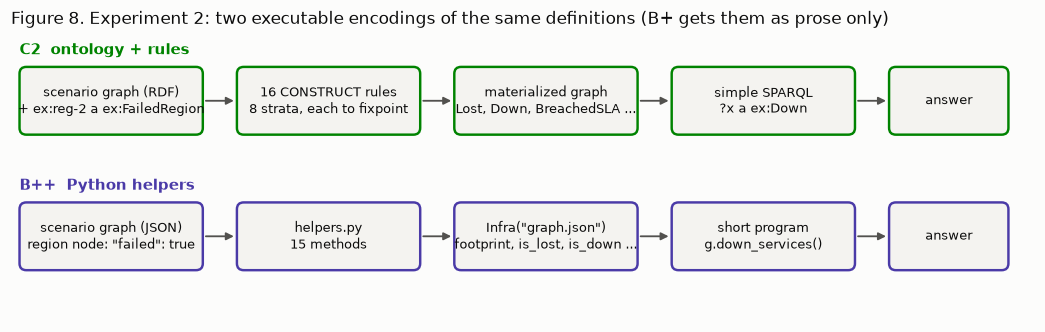

In [13]:
# Figure 8 - the two executable routes from data to answer.
fig, ax = plt.subplots(figsize=(12, 3.4)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 3.4)
def box(x, y, w, txt, c):
    ax.add_patch(FancyBboxPatch((x, y), w, 0.8, boxstyle="round,pad=0,rounding_size=0.08", fc="#f4f3f0", ec=c, lw=1.6))
    ax.text(x + w / 2, y + 0.4, txt, ha="center", va="center", fontsize=8.5)
def arrow(x1, x2, y):
    ax.annotate("", xy=(x2, y), xytext=(x1, y), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.2))
for y, c, steps in [(2.2, COLOR["C2"], ["scenario graph (RDF)\n+ ex:reg-2 a ex:FailedRegion", "16 CONSTRUCT rules\n8 strata, each to fixpoint",
                                         "materialized graph\nLost, Down, BreachedSLA ...", "simple SPARQL\n?x a ex:Down", "answer"]),
                    (0.6, COLOR["Bplusplus"], ["scenario graph (JSON)\nregion node: \"failed\": true", "helpers.py\n15 methods",
                                               "Infra(\"graph.json\")\nfootprint, is_lost, is_down ...", "short program\ng.down_services()", "answer"])]:
    xs = [0.1, 2.65, 5.2, 7.75, 10.3]
    for i, (x, s) in enumerate(zip(xs, steps)):
        box(x, y, 2.15 if i < 4 else 1.4, s, c)
        if i: arrow(xs[i - 1] + 2.15, x, y + 0.4)
ax.text(0.1, 3.15, "C2  ontology + rules", color=COLOR["C2"], fontsize=10, weight="bold")
ax.text(0.1, 1.55, "B++  Python helpers", color=COLOR["Bplusplus"], fontsize=10, weight="bold")
ax.set_title("Figure 8. Experiment 2: two executable encodings of the same definitions (B+ gets them as prose only)",
             loc="left", fontsize=11)
plt.show()

In [14]:
from rules import STRATA, load_materialized
g, stats = load_materialized(EXP2 / "data" / "scenarios" / "graph_500_reg-5.ttl")
display(Markdown("*Rule strata on the 559-node graph with reg-5 failed. Rules that use negation run after everything they negate.*"))
display(pd.DataFrame([(name, len(rules), stats[name][0], stats[name][1]) for name, rules in STRATA],
                     columns=["stratum", "rules", "rounds to fixpoint", "triples derived"]).set_index("stratum"))

*Rule strata on the 559-node graph with reg-5 failed. Rules that use negation run after everything they negate.*

,rules,rounds to fixpoint,triples derived
stratum,,,
type closure,1,3,549
dependency closure,2,6,1990
replica groups,3,2,802
"footprint, replicas",2,2,905
"primary, lost (negation)",2,2,381
down,2,2,137
"SLA breach, tier rule",3,2,78
type closure of derived classes,1,1,0


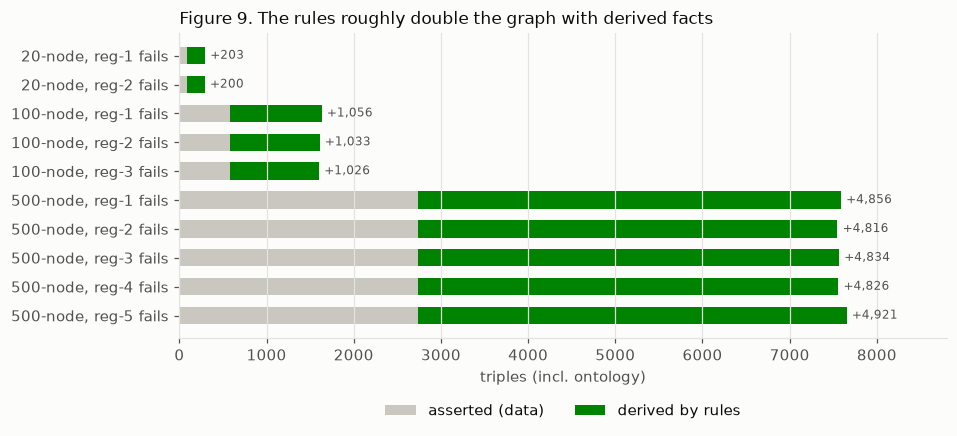

In [15]:
# Figure 9 - how much the rules add: asserted vs derived triples per failure scenario.
from rdflib import Graph
rows = []
for f in sorted((EXP2 / "data" / "scenarios").glob("graph_*.ttl"), key=lambda p: (int(p.stem.split("_")[1]), p.stem)):
    asserted = len(Graph().parse(f)); total = len(Graph().parse(EXP2 / "data" / "materialized" / f.name))
    _, n, r = f.stem.split("_")
    rows.append({"scenario": f"{n}-node, {r} fails", "asserted": asserted, "derived": total - asserted})
mat = pd.DataFrame(rows).set_index("scenario")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(mat.index[::-1], mat.asserted[::-1], color="#c9c7bf", label="asserted (data)", height=0.6)
ax.barh(mat.index[::-1], mat.derived[::-1], left=mat.asserted[::-1], color=COLOR["C2"], label="derived by rules", height=0.6)
for i, (a, d) in enumerate(zip(mat.asserted[::-1], mat.derived[::-1])):
    ax.text(a + d + 60, i, f"+{d:,}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("triples (incl. ontology)"); ax.grid(axis="x", color=GRID); ax.set_xlim(0, 8800)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.set_title("Figure 9. The rules roughly double the graph with derived facts", loc="left", fontsize=11)
plt.show()

### Verification before any model saw a question

Both executable encodings must reproduce the NetworkX ground truth **exactly**, for every concept, every node and
every failure scenario. A negative control plants Experiment 1's pattern-1 bug in the rules (and an off-by-one in the
helpers) to show the check can fail.

In [16]:
import verify_defs
assert verify_defs.main()

size region lost down SLAs  helpers.py rules      materialize  derived max rounds
  20 reg-1     6    7    3  OK         OK                0.2s      124          3
  20 reg-2     4    6    3  OK         OK                0.3s      121          3
 100 reg-1    22   37   11  OK         OK                0.4s      977          6
 100 reg-2    13   26    8  OK         OK                0.4s      954          6
 100 reg-3    10   21    9  OK         OK                0.4s      947          6
 500 reg-1    43   90   33  OK         OK                2.0s     4777          6
 500 reg-2    33   74   19  OK         OK                1.8s     4737          6
 500 reg-3    55   68   21  OK         OK                2.0s     4755          6
 500 reg-4    35   74   27  OK         OK                1.7s     4747          6
 500 reg-5    56  137   38  OK         OK                1.9s     4842          6

concepts checked per scenario: primary, lost, down, breached, tier_risk, violations, group, footp

In [17]:
qs2 = pd.DataFrame(json.loads((EXP2 / "data" / "questions.json").read_text()))
l4 = qs2[qs2.level == "L4"]
kinds = l4.groupby("kind").agg(per_size=("size", lambda s: s.value_counts().max()), total=("qid", "size"),
                               answer_type=("answer_type", "first"),
                               example=("text", "first"))
display(kinds.sort_values("total", ascending=False))
test = l4[l4.split == "test"]
print(f"L4: {len(l4)} questions ({(l4.split == 'dev').sum()} DEV / {len(test)} TEST); "
      f"TEST: {test.text.nunique()} distinct texts (clusters), {(test.answer_type == 'bool').sum()} yes/no")

,per_size,total,answer_type,example
kind,,,,
is_down,4,12,bool,"In this scenario, is svc-179 down?"
sla_breached,3,9,bool,"In this scenario, is sla-70 breached?"
is_lost,3,9,bool,"In this scenario, is db-242 lost?"
down_by_team,2,6,set,"In this scenario, which primary services owned..."
is_tier_risk,2,6,bool,Is svc-635 a tier risk?
violates_edge,2,6,bool,Does the dependsOn edge svc-179->svc-787 viola...
down_cfs,1,3,set,"In this scenario, which primary customer-facin..."
breached_slas,1,3,set,"In this scenario, which SLAs are breached?"
count_down,1,3,number,"In this scenario, how many primary services ar..."


L4: 69 questions (18 DEV / 51 TEST); TEST: 45 distinct texts (clusters), 34 yes/no


**Why a cluster bootstrap.** C2's prompt does not depend on graph size, and B+/B++'s does not change across scenarios
within a size. Questions with identical text therefore get identical prompts and correlated answers. The
pre-registered primary test resamples **distinct question texts**, not questions; the per-question bootstrap is
secondary, and if they disagree the decision follows the cluster test.

## 7. Experiment 2 so far: DEV (preliminary, 18 questions)

> These numbers come from the **DEV** split used to check the harness. They are not the pre-registered test and
> carry no inferential weight: 6 questions per size, 14 text clusters.

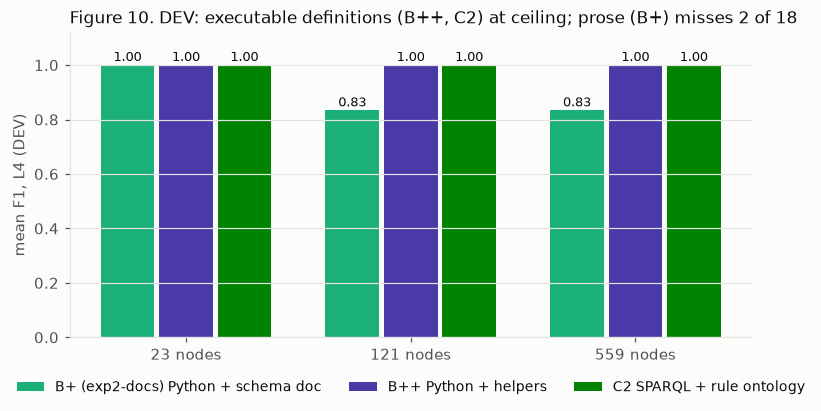

failed-region checks (did each condition find the failed region in the data?): {'Bplus': [1.0, 1.0, 1.0], 'Bplusplus': [1.0, 1.0, 1.0], 'C2': [1.0, 1.0, 1.0]}


In [18]:
# Figure 10 - DEV accuracy on L4 by graph size (value labels on every bar).
conds2 = ["Bplus", "Bplusplus", "C2"]
d4 = s2[s2.level == "L4"]
m = d4.pivot_table(index="size", columns="condition", values="f1")[conds2]
nodes2 = {n: len(truth_for(2, n).nodes) for n in (20, 100, 500)}
fig, ax = plt.subplots(figsize=(8, 3.6)); w = 0.26
for i, c in enumerate(conds2):
    xs = np.arange(3) + (i - 1) * w
    ax.bar(xs, m[c], w * 0.92, color=COLOR[c], label=NAME[c].replace("B+ ", "B+ (exp2-docs) "))
    for x, v in zip(xs, m[c]):
        ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(3), [f"{nodes2[n]} nodes" for n in (20, 100, 500)]); ax.set_ylim(0, 1.12)
ax.set_ylabel("mean F1, L4 (DEV)"); ax.grid(axis="y", color=GRID)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=9)
ax.set_title("Figure 10. DEV: executable definitions (B++, C2) at ceiling; prose (B+) misses 2 of 18",
             loc="left", fontsize=11)
plt.show()
chk = s2[s2.level == "check"].pivot_table(index="qid", columns="condition", values="f1")
print("failed-region checks (did each condition find the failed region in the data?):", chk.to_dict("list"))

In [19]:
rows = []
for other in ("Bplus", "Bplusplus"):
    c, p = cluster_bootstrap(d4, "C2", other), paired_bootstrap(d4, "C2", other)
    rows.append({"comparison": f"C2 - {SHORT[other]}", "mean ΔF1": c["diff"],
                 "cluster CI (primary)": f"[{c['lo']:+.3f}, {c['hi']:+.3f}]",
                 "per-question CI (secondary)": f"[{p['lo']:+.3f}, {p['hi']:+.3f}]",
                 "questions / clusters": f"{c['n']} / {c['clusters']}"})
display(Markdown("*DEV only, not the pre-registered test.*"))
display(pd.DataFrame(rows).set_index("comparison"))
eff2 = s2.groupby("condition").agg(retry_rate=("retries", lambda x: (x > 0).mean()), median_latency_s=("latency_s", "median"),
                                   tokens_in=("tokens_in", "mean"), tokens_out=("tokens_out", "mean"), cost=("cost_usd", "sum"))
display(eff2.loc[conds2])

*DEV only, not the pre-registered test.*

,mean ΔF1,cluster CI (primary),per-question CI (secondary),questions / clusters
comparison,,,,
C2 - B+,0.111,"[+0.000, +0.238]","[+0.000, +0.278]",18 / 14
C2 - B++,0.000,"[+0.000, +0.000]","[+0.000, +0.000]",18 / 14


,retry_rate,median_latency_s,tokens_in,tokens_out,cost
condition,,,,,
Bplus,0.0,8.545,1373.857,890.952,0.122
Bplusplus,0.0,1.345,1708.857,150.714,0.052
C2,0.0,2.464,1766.524,192.762,0.057


In [20]:
# Authoring effort: what it took to make the definitions executable (line and fix counts; no time measure).
import ast
def code_lines(path):
    src = path.read_text(); tree = ast.parse(src); doc = set()
    for node in ast.walk(tree):
        if isinstance(node, (ast.Module, ast.ClassDef, ast.FunctionDef)) and ast.get_docstring(node):
            d = node.body[0]; doc |= set(range(d.lineno, d.end_lineno + 1))
    return sum(1 for i, l in enumerate(src.splitlines(), 1) if l.strip() and not l.strip().startswith("#") and i not in doc)
ttl = [l for l in (EXP2 / "ontology2.ttl").read_text().splitlines() if l.strip() and not l.strip().startswith("#")]
display(pd.DataFrame({
    "artifact": ["helpers.py", "rules.py", "ontology2.ttl"], "condition": ["B++", "C2", "C2"],
    "code lines": [code_lines(EXP2 / "helpers.py"), code_lines(EXP2 / "rules.py"), len(ttl)],
    "units": ["15 methods", f"{sum(len(r) for _, r in STRATA)} rules in {len(STRATA)} strata", "6 derived classes, 4 derived properties"],
    "fixes before matching truth": [0, 1, 0]}).set_index("artifact"))

,condition,code lines,units,fixes before matching truth
artifact,,,,
helpers.py,B++,88,15 methods,0
rules.py,C2,72,16 rules in 8 strata,1
ontology2.ttl,C2,50,"6 derived classes, 4 derived properties",0


## 8. Status, predictions and limitations

**Experiment 1 (complete).** The pre-registered test does **not** support the thesis: C − B+ = −0.005
[−0.055, +0.055]. Grounding of either kind clearly beats the LLM alone (C − A = +0.16), and the gap grows with graph
size. The ontology's weakness was concentrated in region-failure logic that the model had to derive in SPARQL.

**Experiment 2 (pre-registered, TEST pending).** `exp2/PREREG_EXP2.md` fixes the analysis before any TEST question is
sent:

- **Primary:** C2 − B+ on 51 TEST L4 questions, cluster bootstrap over 45 question texts. Supported only if the lower
  bound is above 0.
- **Secondary:** the same with the per-question bootstrap; if the two disagree, the decision follows the cluster CI
  and the result is reported as sensitive to the correlation assumption.
- **Prediction for C2 − B++: a tie.** A C2 win over B+ together with a C2/B++ tie would be evidence for *encoded
  definitions over prose*, in either form, **not** for ontologies over code.

**Limitations (both experiments):** synthetic graphs from one generator; one model and one run at temperature 0;
I wrote the ontology, the questions and the ground truth (circularity risk); ontology construction cost
not measured in human hours; best-effort sandbox; small per-cell counts make every subgroup result exploratory;
Experiment 2's DEV shows a ceiling, so its TEST may be unable to separate C2 from B++; 34 of its 51 TEST questions are
yes/no. Experiment 1 also carried definitions in shared question text, the gap Experiment 2 was designed to close.